# Gene-TU relationship inspection for enlarged dataset

In [23]:
import os
out_dir = os.path.expanduser("~/work/vEcoli/reading/results/gene_tu_matrix")
os.makedirs(out_dir, exist_ok=True)

## Step 1
1. extract gene/tu list and mapping matrix from simdata - type: scipy.sparse.csr_matrix
2. visualize extracted matrix - done, easy to do with plt.spy()
3. compare the KO simulations and alternative media simulations to basal media, wildtype simulation - all identical

Matrix shape (cistrons x TUs): (4538, 3277)
Type: <class 'scipy.sparse._csr.csr_matrix'>

#cistrons: 4538
#TUs: 3277


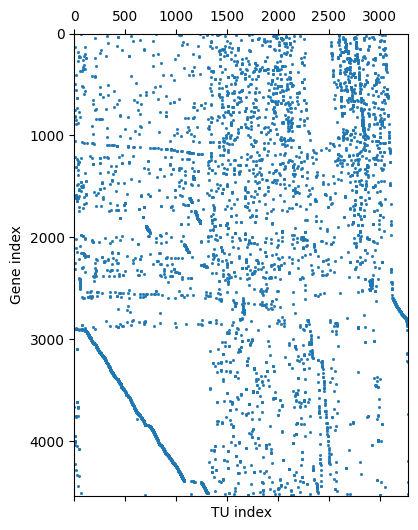

In [38]:
import pickle
import numpy as np
import pandas as pd
import networkx as nx
# Function to load gene-to-TU mapping information from simulation data
def load_gene_tu_info(project_name):
    path = f"/user/home/il22158/work/vEcoli/out/{project_name}/parca/kb/simData.cPickle"
    with open(path, "rb") as f:
        sim_data = pickle.load(f)
    # ----------------------------
    # Mapping matrix
    # ----------------------------
    M = sim_data.process.transcription.cistron_tu_mapping_matrix
    cistron_ids = np.array(sim_data.process.transcription.cistron_data["id"])
    rna_ids = np.array(sim_data.process.transcription.rna_data["id"])
    return M, cistron_ids, rna_ids
# Load gene-to-TU mapping information from the basal simulation data
project_name = "wildtype_basal"
M0, cistron_ids0, rna_ids0 = load_gene_tu_info(project_name)

# Print basic information about the mapping matrix and ID lists
print("Matrix shape (cistrons x TUs):", M0.shape)
print("Type:", type(M0))
print("\n#cistrons:", len(cistron_ids0))
print("#TUs:", len(rna_ids0))

# Visualize the mapping matrix
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.spy(M0, markersize=1)
plt.xlabel("TU index")
plt.ylabel("Gene index")
plt.savefig(f"{out_dir}/gene_tu_matrix.png", bbox_inches="tight")
plt.show()

In [10]:
## Compare the matrix between 4 media conditions
alter_projects = {
    "acetate": "wildtype_acetate",
    "succinate": "wildtype_succinate",
    "with_aa": "wildtype_with_aa",
}
gene_tu_info = {cond: load_gene_tu_info(project_name) for cond, project_name in alter_projects.items()}
# Check cirston/TU ID lists
for cond, (M, cistron_ids, rna_ids) in gene_tu_info.items():
    print(f"Checking condition: {cond}")
    if cistron_ids0.tolist() != cistron_ids.tolist():
        print(f"Cistron IDs differ for condition {cond}")
    if rna_ids0.tolist() != rna_ids.tolist():
        print(f"RNA IDs differ for condition {cond}")
    if M0.shape != M.shape:
        print(f"Mapping matrix shape differs for condition {cond}")
    if not np.all(M0.toarray() == M.toarray()):
        print(f"Mapping matrix content differs for condition {cond}")
    else:
        print(f"Mapping matrix is identical for condition {cond}")

Checking condition: acetate
Mapping matrix is identical for condition acetate
Checking condition: succinate
Mapping matrix is identical for condition succinate
Checking condition: with_aa
Mapping matrix is identical for condition with_aa


In [11]:
## Compare KO simulation to wildtype simulation
ko_projects = [
    "gene_knockout_EG10001_succinate",
    "gene_knockout_EG10001_with_aa",
    "gene_knockout_462KO_basal_operon_on_p5",
    "gene_knockout_EG10001_acetate"
]
ko_gene_tu_info = {project_name: load_gene_tu_info(project_name) for project_name in ko_projects}

# Check cistron/TU ID lists for KO simulations
for project_name, (M, cistron_ids, rna_ids) in ko_gene_tu_info.items():
    print(f"Checking KO project: {project_name}")
    if cistron_ids0.tolist() != cistron_ids.tolist():
        print(f"Cistron IDs differ for KO project {project_name}")
    if rna_ids0.tolist() != rna_ids.tolist():
        print(f"RNA IDs differ for KO project {project_name}")
    if M0.shape != M.shape:
        print(f"Mapping matrix shape differs for KO project {project_name}")
    if not np.all(M0.toarray() == M.toarray()):
        print(f"Mapping matrix content differs for KO project {project_name}")
    else:
        print(f"Mapping matrix is identical for KO project {project_name}")

Checking KO project: gene_knockout_EG10001_succinate
Mapping matrix is identical for KO project gene_knockout_EG10001_succinate
Checking KO project: gene_knockout_EG10001_with_aa
Mapping matrix is identical for KO project gene_knockout_EG10001_with_aa
Checking KO project: gene_knockout_462KO_basal_operon_on_p5
Mapping matrix is identical for KO project gene_knockout_462KO_basal_operon_on_p5
Checking KO project: gene_knockout_EG10001_acetate
Mapping matrix is identical for KO project gene_knockout_EG10001_acetate


## Step 2
1. check how much the implemented KO covered in the map, KO gene list: /user/home/il22158/work/vEcoli/reading/imported/Single_KO_RNA_names.txt
2. visualize the range

`gene_konckout.py` function: \
`apply_variant` resolves a gene to its TU index/indices and sets their expression factors to zero (gene_knockout.py). With the operon-on configuration, those associated TUs are disabled together (operon-on config). 

KO genes found: 462/462
Unmatched KO genes: []
Covered TUs: 452/3277


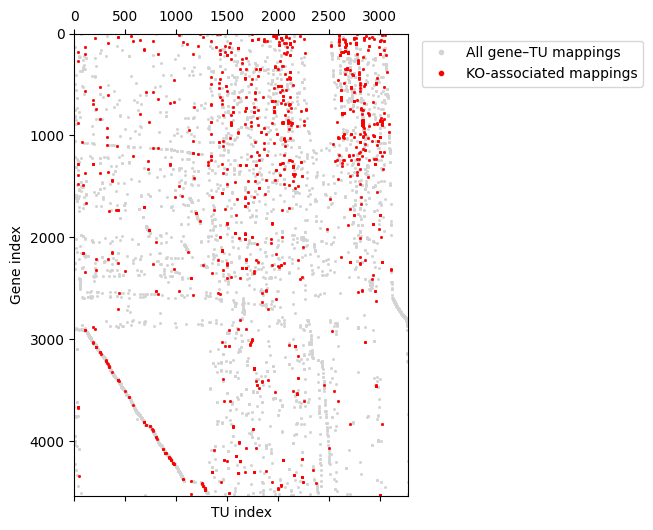

In [36]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ko_ids = set(Path(
    "/user/home/il22158/work/vEcoli/reading/imported/Single_KO_RNA_names.txt"
).read_text().split())

gene_ids = np.array([str(cid).removesuffix("_RNA") for cid in cistron_ids0])
ko_rows = np.flatnonzero(np.isin(gene_ids, list(ko_ids)))

tu_mask = np.asarray(M0[ko_rows, :].getnnz(axis=0)).ravel() > 0
ko_map = M0.multiply(tu_mask).tocsr()
ko_map.eliminate_zeros()

print(f"KO genes found: {len(set(gene_ids[ko_rows]))}/{len(ko_ids)}")
print("Unmatched KO genes:", sorted(ko_ids - set(gene_ids)))
print(f"Covered TUs: {tu_mask.sum()}/{M0.shape[1]}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.spy(M0, markersize=1, color="lightgray")
ax.spy(ko_map, markersize=1, color="red")
ax.set_xlabel("TU index")
ax.set_ylabel("Gene index")
ax.legend(handles=[
    Line2D([], [], marker=".", color="lightgray", linestyle="None",
           label="All gene–TU mappings"),
    Line2D([], [], marker=".", color="red", linestyle="None",
           label="KO-associated mappings"),
], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.savefig(f"{out_dir}/gene_tu_KO_experiment0.png", bbox_inches="tight")
plt.show()

Resolved KOs: 462/462
KOs with identical complete TU sets: 150
Identical TU-set groups: 53
Redundant KOs beyond one per identical set: 97
TUs disabled by more than one KO (including partial overlaps): 91


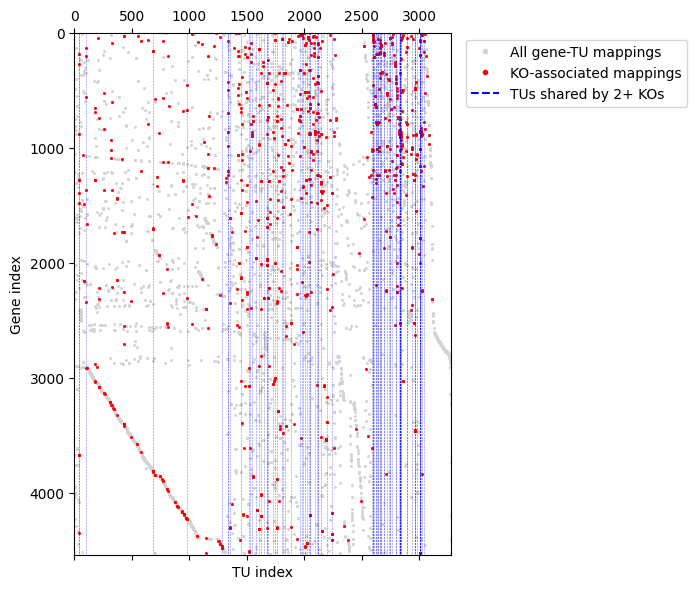

In [35]:
# Background: 
# A gene can belong to multiple TUs, for example when an operon has internal
# promoters or terminators. This model disables every TU containing the KO gene.
# Other genes on those TUs are affected but can still be expressed from other TUs;
# those other TUs are not recursively disabled. This is model-specific KO behavior.

# Results explanation:
# Identical-set KOs (150 previously): count genes whose complete TU sets match another KO.
# Groups (53): count distinct complete TU sets shared by at least two KOs.
# Redundant KOs (97): sum group size minus one, or 150 - 53.
# Shared TUs (91): count individual TUs disabled by at least two KOs, even if their
# complete TU sets differ. This counts TUs, not KOs, so it need not equal 150.
from collections import defaultdict

with open("/user/home/il22158/work/vEcoli/out/wildtype_basal/parca/kb/simData.cPickle", "rb") as f:
    transcription = pickle.load(f).process.transcription

actual_genes = transcription.cistron_data["gene_id"]
actual_rows = np.flatnonzero(np.isin(actual_genes, list(ko_ids)))
if (not np.array_equal(transcription.cistron_data["id"], cistron_ids0)
        or not np.array_equal(transcription.rna_data["id"], rna_ids0)
        or not np.array_equal(actual_rows, ko_rows)
        or not np.array_equal(actual_genes[ko_rows], gene_ids[ko_rows])
        or len(ko_rows) != len(ko_ids)
        or set(actual_genes[ko_rows]) != ko_ids):
    raise ValueError("Previous KO rows do not uniquely match the knockout gene IDs")

ko_by_tu_set = defaultdict(list)
ko_by_tu = defaultdict(list)
for row in ko_rows:
    ko_id = str(gene_ids[row])
    tu_set = tuple(sorted(M0.getrow(row).nonzero()[1]))
    if not tu_set:
        raise ValueError(f"No TUs found for KO {ko_id}")
    ko_by_tu_set[tu_set].append(ko_id)
    for index in tu_set:
        ko_by_tu[index].append(ko_id)

same_tu_sets = [(indices, genes) for indices, genes in ko_by_tu_set.items() if len(genes) > 1]
shared_tus = [(index, genes) for index, genes in ko_by_tu.items() if len(genes) > 1]
print(f"Resolved KOs: {sum(map(len, ko_by_tu_set.values()))}/{len(ko_ids)}")
print(f"KOs with identical complete TU sets: {sum(len(genes) for _, genes in same_tu_sets)}")
print(f"Identical TU-set groups: {len(same_tu_sets)}")
print(f"Redundant KOs beyond one per identical set: {sum(len(genes) - 1 for _, genes in same_tu_sets)}")
print(f"TUs disabled by more than one KO (including partial overlaps): {len(shared_tus)}")

identical_ko_tu_sets = pd.DataFrame([
    {"KO count": len(genes), "KO IDs": ", ".join(genes),
     "Disabled TUs": ", ".join(str(rna_ids0[i]) for i in indices)}
    for indices, genes in same_tu_sets
], columns=["KO count", "KO IDs", "Disabled TUs"])

shared_tus_by_ko = pd.DataFrame([
    {"TU ID": str(rna_ids0[index]), "KO count": len(genes), "KO IDs": ", ".join(genes)}
    for index, genes in shared_tus
], columns=["TU ID", "KO count", "KO IDs"])
identical_ko_tu_sets.to_csv(f"{out_dir}/identical_ko_tu_sets.csv", index=False)
shared_tus_by_ko.to_csv(f"{out_dir}/shared_tus_by_ko.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.spy(M0, markersize=1, color="lightgray")
ax.spy(ko_map, markersize=1, color="red")
ax.vlines([index for index, _ in shared_tus], -0.5, M0.shape[0] - 0.5,
          colors="blue", linestyles="dashed", linewidth=0.4, alpha=0.5)
ax.set_ylim(M0.shape[0] - 0.5, -0.5)
ax.set_xlabel("TU index")
ax.set_ylabel("Gene index")
ax.legend(handles=[
    Line2D([], [], marker=".", color="lightgray", linestyle="None", label="All gene-TU mappings"),
    Line2D([], [], marker=".", color="red", linestyle="None", label="KO-associated mappings"),
    Line2D([], [], color="blue", linestyle="dashed", label="TUs shared by 2+ KOs"),
], loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
fig.savefig(f"{out_dir}/gene_tu_KO_experiment.png", bbox_inches="tight")
plt.show()

# Archived: Inspect rest of operons (copied from Baseline Regression)

## TU list
Extracted relationship saved to: "/user/home/il22158/work/vEcoli/reading/cistron_tu_mapping.csv"\
Simdata read from a gene_knockout_test1 simluation.

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

sim_data_path = "/user/home/il22158/work/vEcoli/out/gene_knockout_test1/parca/kb/simData.cPickle"

# ----------------------------
# Load sim_data
# ----------------------------
with open(sim_data_path, "rb") as f:
    sim_data = pickle.load(f)

# ----------------------------
# Extract objects
# ----------------------------
# This is the key mapping matrix used throughout your code
M = sim_data.process.transcription.cistron_tu_mapping_matrix

print("Matrix shape (cistrons x TUs):", M.shape)
print("Type:", type(M))

# ----------------------------
# Load ID lists
# ----------------------------
cistron_ids = sim_data.process.transcription.cistron_data["id"]
rna_ids = sim_data.process.transcription.rna_data["id"]

print("\n#cistrons:", len(cistron_ids))
print("#TUs:", len(rna_ids))

# ----------------------------
# Function: gene -> TU mapping
# ----------------------------
def cistron_to_tus(cistron_id):
    idx = np.where(cistron_ids == cistron_id)[0][0]
    tu_indexes = M.getrow(idx).nonzero()[1]
    return [rna_ids[i] for i in tu_indexes]

# ----------------------------
# Pick a gene to inspect
# ----------------------------
test_gene = cistron_ids[0]   # change this to any gene ID you want
mapped_tus = cistron_to_tus(test_gene)

print(f"\nGene (cistron): {test_gene}")
print("Mapped TU(s):")
for tu in mapped_tus:
    print("  ", tu)

# ----------------------------
# Check if one gene maps to multiple TUs
# ----------------------------
multi_map_genes = []
for i, cid in enumerate(cistron_ids):
    n_tus = M.getrow(i).getnnz()
    if n_tus > 1:
        multi_map_genes.append((cid, n_tus))

print("\nGenes mapping to multiple TUs:", len(multi_map_genes))
print("Example:", multi_map_genes[:10])

Matrix shape (cistrons x TUs): (4538, 3277)
Type: <class 'scipy.sparse._csr.csr_matrix'>

#cistrons: 4538
#TUs: 3277

Gene (cistron): EG10001_RNA
Mapped TU(s):
   TU0-14120[c]

Genes mapping to multiple TUs: 694
Example: [(np.str_('EG10007_RNA'), 2), (np.str_('EG10022_RNA'), 2), (np.str_('EG10023_RNA'), 2), (np.str_('EG10024_RNA'), 2), (np.str_('EG10025_RNA'), 2), (np.str_('EG10026_RNA'), 2), (np.str_('EG10027_RNA'), 2), (np.str_('EG10036_RNA'), 2), (np.str_('EG10037_RNA'), 2), (np.str_('EG10047_RNA'), 4)]


In [ ]:
import pickle
import numpy as np
import pandas as pd
import os

sim_data_path = "/user/home/il22158/work/vEcoli/out/gene_knockout_test1/parca/kb/simData.cPickle"
out_path = "/user/home/il22158/work/vEcoli/reading/cistron_tu_mapping.csv"

# ----------------------------
# Load sim_data
# ----------------------------
with open(sim_data_path, "rb") as f:
    sim_data = pickle.load(f)

# ----------------------------
# Extract matrix + IDs
# ----------------------------
M = sim_data.process.transcription.cistron_tu_mapping_matrix
cistron_ids = np.array(sim_data.process.transcription.cistron_data["id"])
rna_ids = np.array(sim_data.process.transcription.rna_data["id"])

print("Matrix shape:", M.shape)

# ----------------------------
# Convert to edge list
# ----------------------------
rows, cols = M.nonzero()

data = {
    "cistron_id": [],
    "tu_id": []
}

for i, j in zip(rows, cols):
    data["cistron_id"].append(cistron_ids[i])
    data["tu_id"].append(rna_ids[j])

df = pd.DataFrame(data)

print(f"Total mappings (edges): {len(df)}")

# ----------------------------
# OPTIONAL: add gene symbols safely
# ----------------------------
try:
    symbols = sim_data.process.transcription.cistron_data["symbol"]
    symbol_map = {cid: sym for cid, sym in zip(cistron_ids, symbols)}
    df["symbol"] = df["cistron_id"].map(symbol_map)
except Exception as e:
    print("No symbol field found, skipping symbols:", e)

# ----------------------------
# Save CSV
# ----------------------------
os.makedirs(os.path.dirname(out_path), exist_ok=True)
df.to_csv(out_path, index=False)

print("Saved to:", out_path)

Matrix shape: (4538, 3277)
Total mappings (edges): 5433
No symbol field found, skipping symbols: 'symbol'
Saved to: /user/home/il22158/work/vEcoli/reading/cistron_tu_mapping.csv


In [ ]:
import pickle
import numpy as np
import pandas as pd
import networkx as nx

sim_data_path = "/user/home/il22158/work/vEcoli/out/gene_knockout_test1/parca/kb/simData.cPickle"
out_path = "/user/home/il22158/work/vEcoli/reading/cistron_to_tu_grouped.csv" 

with open(sim_data_path, "rb") as f:
    sim_data = pickle.load(f)

# ----------------------------
# Mapping matrix
# ----------------------------
M = sim_data.process.transcription.cistron_tu_mapping_matrix

cistron_ids = np.array(sim_data.process.transcription.cistron_data["id"])
rna_ids = np.array(sim_data.process.transcription.rna_data["id"])

n_tus = M.shape[1]

# ----------------------------
# Step 1: TU → genes mapping
# ----------------------------
tu_to_genes = {j: set() for j in range(n_tus)}

for i in range(M.shape[0]):
    tu_idx = M.getrow(i).nonzero()[1]
    for j in tu_idx:
        tu_to_genes[j].add(i)

# ----------------------------
# Step 2: Build TU overlap graph
# (edge if share ≥1 gene)
# ----------------------------
G = nx.Graph()
G.add_nodes_from(range(n_tus))

for i in range(n_tus):
    for j in range(i + 1, n_tus):
        if tu_to_genes[i] & tu_to_genes[j]:
            G.add_edge(i, j)

# ----------------------------
# Step 3: Connected components = operons
# ----------------------------
components = list(nx.connected_components(G))

tu_to_operon = {}
for op_id, comp in enumerate(components):
    for tu in comp:
        tu_to_operon[tu] = op_id

print(f"Detected operons: {len(components)}")

# ----------------------------
# Step 4: Build rows (cistron → TU → operon)
# ----------------------------
rows = []

for i, cid in enumerate(cistron_ids):

    tu_idx = M.getrow(i).nonzero()[1]
    tus = [rna_ids[j] for j in tu_idx]

    operon_ids = {tu_to_operon[j] for j in tu_idx if j in tu_to_operon}

    rows.append({
        "cistron_id": cid,
        "num_tus": len(tus),
        "tu_ids": ";".join(tus),

        "num_operons": len(operon_ids),
        "operon_ids": ";".join(map(str, sorted(operon_ids)))
    })

df = pd.DataFrame(rows)
df.to_csv(out_path, index=False)

print("Saved mapping to:", out_path)
print("Rows:", len(df))

Detected operons: 2753
Saved mapping to: /user/home/il22158/work/vEcoli/reading/cistron_to_tu_grouped.csv
Rows: 4538


## Operon list
Extracted relationship saved to: "/user/home/il22158/work/vEcoli/reading/imported/inferred_operons_from_TUs.csv"

**Operon number difference?**
1. What the paper says (ground truth baseline)

Sun et al. (2024) report:

~2569 operons total
788 polycistronic operons
remainder mostly monocistronic
operons are curated regulatory units (EcoCyc + model curation)

So their number is:

✔ biologically curated operon count

2. What your 2753 represents

Your number comes from:

connected components of a TU–TU overlap graph

So it is:

❗ a data-derived clustering of TUs, not curated operons

That alone already means:

it is not expected to match exactly
it can differ by ±100–300 easily

In [ ]:
import numpy as np

cistron_data = sim_data.process.transcription.cistron_data.struct_array

gene_to_cistron = {}

for c in cistron_data:
    g = c["gene_id"]
    gene_to_cistron.setdefault(g, set()).add(c["id"])

# check if any gene maps to multiple cistrons
multi = {g: ids for g, ids in gene_to_cistron.items() if len(ids) > 1}

print("Genes with multiple cistrons:", len(multi))
print(list(multi.items())[:10])

Genes with multiple cistrons: 0
[]


In [ ]:
import pandas as pd

tu_file = "/user/home/il22158/work/vEcoli/reading/imported/total_unique_TUs.csv"

df = pd.read_csv(tu_file)

tus = df["tu_id"].astype(str).str.strip().unique()

print("Total raw TU rows:", len(df))
print("Unique TU IDs:", len(tus))
print("Example:", tus[:10])

Total raw TU rows: 350
Unique TU IDs: 350
Example: ['EG10016_RNA[c]' 'EG10214_RNA[c]' 'EG10383_RNA[c]' 'EG10901_RNA[c]'
 'EG10982_RNA[c]' 'EG12662_RNA[c]' 'EG12663_RNA[c]' 'TU0-0[c]'
 'TU0-1002[c]' 'TU0-1021[c]']


In [ ]:
""" Use the hierarchical TU → cistron mapping to infer operon groups based on shared cistrons.
"""

import pandas as pd

# ----------------------------
# Paths
# ----------------------------
tu_file = "/user/home/il22158/work/vEcoli/reading/imported/total_unique_TUs.csv"
map_file = "/user/home/il22158/work/vEcoli/reading/cistron_to_tu_grouped.csv" # Read from simData, see the last section.

out_file = "/user/home/il22158/work/vEcoli/reading/imported/inferred_operons_from_TUs.csv"

# ----------------------------
# Load data
# ----------------------------
tu_df = pd.read_csv(tu_file)
map_df = pd.read_csv(map_file)

target_tus = set(tu_df["tu_id"].astype(str))

# ----------------------------
# Build TU → cistron membership
# ----------------------------
tu_to_cistrons = {}

for _, row in map_df.iterrows():
    cistron = row["cistron_id"]
    tus = str(row["tu_ids"]).split(";")

    for tu in tus:
        tu = tu.strip()
        if tu:
            tu_to_cistrons.setdefault(tu, set()).add(cistron)

# ----------------------------
# Build cistron → TU set + operons (NEW: keep real operons)
# ----------------------------
cistron_to_tus = {}
cistron_to_operons = {}

for _, row in map_df.iterrows():
    cistron = row["cistron_id"]

    tus = [t.strip() for t in str(row["tu_ids"]).split(";") if t.strip()]
    ops = [o.strip() for o in str(row["operon_ids"]).split(";") if o.strip()]

    cistron_to_tus[cistron] = set(tus)
    cistron_to_operons[cistron] = set(ops)

# ----------------------------
# Infer operon groups (TU clustering via shared cistrons)
# ----------------------------
visited_tus = set()
operons = []

for tu in target_tus:
    if tu in visited_tus:
        continue

    stack = [tu]
    cluster_tus = set()
    cluster_operons = set()

    while stack:
        current_tu = stack.pop()
        if current_tu in visited_tus:
            continue

        visited_tus.add(current_tu)
        cluster_tus.add(current_tu)

        # expand via shared cistrons
        for cistron in tu_to_cistrons.get(current_tu, []):

            # NEW: collect real operon IDs directly from mapping file
            cluster_operons.update(cistron_to_operons.get(cistron, []))

            for linked_tu in cistron_to_tus.get(cistron, []):
                if linked_tu not in visited_tus:
                    stack.append(linked_tu)

    operons.append({
        "tus": sorted(cluster_tus),
        "operons": sorted(cluster_operons)
    })

# ----------------------------
# Save results (NO synthetic IDs anymore)
# ----------------------------
rows = []

for op in operons:
    rows.append({
        "operon_ids": ";".join(op["operons"]),   # ← real IDs from map file
        "num_operons": len(op["operons"]),
        "num_tus": len(op["tus"]),
        "tu_ids": ";".join(op["tus"])
    })

out_df = pd.DataFrame(rows)
out_df.to_csv(out_file, index=False)

print("Saved:", out_file)
print("Unique clusters:", len(out_df))
print("Total TU covered:", sum(len(set(r['tu_ids'].split(';'))) for r in rows))

Saved: /user/home/il22158/work/vEcoli/reading/imported/inferred_operons_from_TUs.csv
Unique clusters: 334
Total TU covered: 550


### Compare implemented KOs and high-expression operons

In [ ]:
import pandas as pd
import ast

# ----------------------------
# Paths
# ----------------------------
s3_path = "/user/home/il22158/work/vEcoli/reading/imported/Sun_et_al_S3.csv"
genes_path = "/user/home/il22158/work/vEcoli/reconstruction/ecoli/flat/genes.tsv"
map_path = "/user/home/il22158/work/vEcoli/reading/cistron_to_tu_grouped.csv"

out_path = "/user/home/il22158/work/vEcoli/reading/imported/paper_operons_mapped.csv"

# ----------------------------
# Load data
# ----------------------------
s3 = pd.read_csv(s3_path)
genes = pd.read_csv(genes_path, sep="\t", comment="#")
map_df = pd.read_csv(map_path)

# ----------------------------
# Build gene symbol → RNA/cistron mapping
# ----------------------------
symbol_to_rna = {}

for _, row in genes.iterrows():
    symbol = row["symbol"]

    if isinstance(row["rna_ids"], str):
        rnas = ast.literal_eval(row["rna_ids"])
    else:
        rnas = row["rna_ids"]

    for r in rnas:
        symbol_to_rna[symbol] = r

# ----------------------------
# Build cistron → operon_ids mapping
# ----------------------------
cistron_to_ops = {}

for _, row in map_df.iterrows():
    cistron = row["cistron_id"]
    ops = [o.strip() for o in str(row["operon_ids"]).split(";") if o.strip()]
    cistron_to_ops[cistron] = set(ops)

# ----------------------------
# Select paper operons
# ----------------------------
high = s3[s3["Mean protein copy numbers"] >= 100]

rows = []

# ----------------------------
# Map paper genes → RNA/cistrons → operon IDs
# ----------------------------
for _, row in high.iterrows():

    genes_list = [g.strip() for g in str(row["Constituent gene names"]).split(",")]

    print("\n======================================")
    print("Paper genes:", genes_list)

    matched_ops = set()

    for g in genes_list:

        if g not in symbol_to_rna:
            print(f"{g}: NOT FOUND in genes.tsv")
            continue

        rna = symbol_to_rna[g]

        print(f"{g} -> RNA/cistron: {rna}")

        if rna not in cistron_to_ops:
            print(f"    {rna}: NOT FOUND in cistron_to_tu_grouped.csv")
            continue

        ops = cistron_to_ops[rna]

        print(f"    {rna} -> operons {sorted(ops)}")

        matched_ops.update(ops)

    print("Matched operons:", sorted(matched_ops))

    rows.append({
        "paper_gene_set": ";".join(genes_list),
        "operon_ids": ";".join(sorted(matched_ops)),
        "num_operons": len(matched_ops)
    })

# ----------------------------
# Save
# ----------------------------
out_df = pd.DataFrame(rows)
out_df.to_csv(out_path, index=False)

print("\nSaved:", out_path)
print("Rows:", len(out_df))


Paper genes: ['ahpC', 'ahpF']
ahpC -> RNA/cistron: EG11384_RNA
    EG11384_RNA -> operons ['31']
ahpF -> RNA/cistron: EG11385_RNA
    EG11385_RNA -> operons ['31']
Matched operons: ['31']

Paper genes: ['gapA', 'yeaD']
gapA -> RNA/cistron: EG10367_RNA
    EG10367_RNA -> operons ['573']
yeaD -> RNA/cistron: G6966_RNA
    G6966_RNA -> operons ['573']
Matched operons: ['573']

Paper genes: ['rplK', 'rplA', 'rplJ', 'rplL', 'rpoB', 'rpoC']
rplK -> RNA/cistron: EG10872_RNA
    EG10872_RNA -> operons ['1809']
rplA -> RNA/cistron: EG10864_RNA
    EG10864_RNA -> operons ['1809']
rplJ -> RNA/cistron: EG10871_RNA
    EG10871_RNA -> operons ['1809']
rplL -> RNA/cistron: EG10873_RNA
    EG10873_RNA -> operons ['1809']
rpoB -> RNA/cistron: EG10894_RNA
    EG10894_RNA -> operons ['1809']
rpoC -> RNA/cistron: EG10895_RNA
    EG10895_RNA -> operons ['1809']
Matched operons: ['1809']

Paper genes: ['tufA', 'fusA', 'rpsG', 'rpsL']
tufA -> RNA/cistron: EG11036_RNA
    EG11036_RNA -> operons ['1410']
fusA

In [ ]:
import pandas as pd

# ----------------------------
# Paths
# ----------------------------
paper_path = "/user/home/il22158/work/vEcoli/reading/imported/paper_operons_mapped.csv"
your_operons_path = "/user/home/il22158/work/vEcoli/reading/imported/inferred_operons_from_TUs.csv"

# ----------------------------
# Load data
# ----------------------------
paper_df = pd.read_csv(paper_path)
your_df = pd.read_csv(your_operons_path)

# ----------------------------
# Build PAPER operon sets
# ----------------------------
paper_operons = []

for _, row in paper_df.iterrows():
    ops = [o.strip() for o in str(row["operon_ids"]).split(";") if o.strip()]
    if ops:
        paper_operons.append(set(ops))

# ----------------------------
# Build YOUR operon sets
# ----------------------------
your_operons = []

for _, row in your_df.iterrows():
    ops = [o.strip() for o in str(row["operon_ids"]).split(";") if o.strip()]
    if ops:
        your_operons.append(set(ops))

# ----------------------------
# Binary overlap check
# ----------------------------
overlapped = 0
not_overlapped = 0

for p_ops in paper_operons:

    found = False

    for y_ops in your_operons:

        if len(p_ops & y_ops) > 0:
            found = True
            break

    if found:
        overlapped += 1
    else:
        not_overlapped += 1

# ----------------------------
# Results
# ----------------------------
print("Paper operons:", len(paper_operons))
print("Your operons:", len(your_operons))
print("Overlapped:", overlapped)
print("Not overlapped:", not_overlapped)

Paper operons: 397
Your operons: 334
Overlapped: 131
Not overlapped: 266
